Saving Titanic-Dataset.csv to Titanic-Dataset (5).csv
0
28.0
Đánh giá Random Forest:
Accuracy:  0.8212290502793296
Precision:  0.8135593220338984
Recall:  0.6956521739130435
F1 score:  0.75
Đánh giá XG Boost:
Accuracy:  0.8156424581005587
Precision:  0.7647058823529411
Recall:  0.7536231884057971
F1 score:  0.7591240875912408


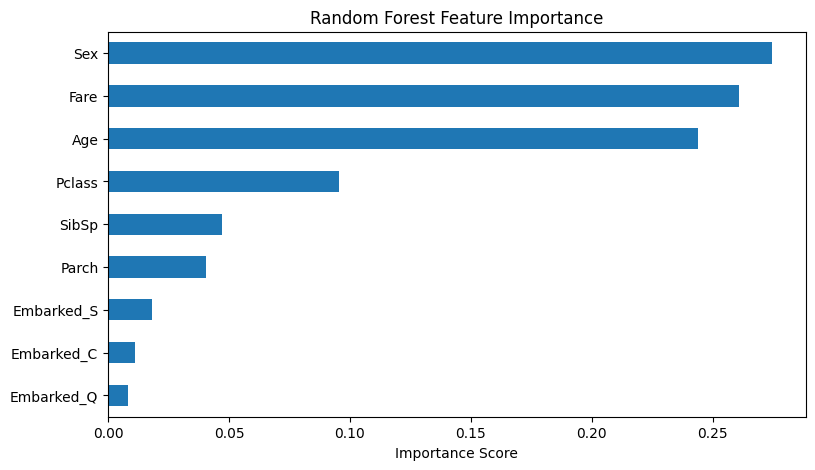

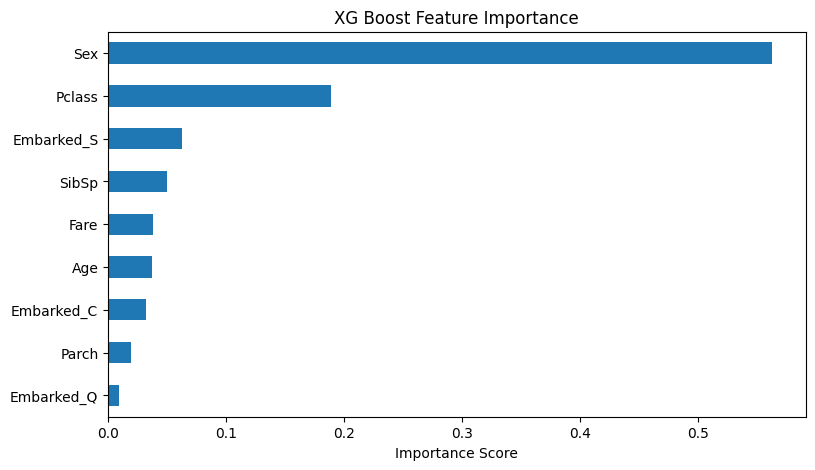

Best Parameters:  {'max_depth': 3, 'n_estimators': 100}
Accuracy: 0.8044692737430168


<IPython.core.display.Javascript object>

,params.max_depth,params.n_estimators,metrics.accuracy
0,3,100,0.804469
1,None,100,0.815642
2,None,100,0.815642
3,None,100,0.815642
4,None,100,0.815642
5,None,100,0.815642


In [6]:
from google.colab import files
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
%pip install mlflow
import mlflow
from google.colab import output
import subprocess

uploaded = files.upload()
df = pd.read_csv("Titanic-Dataset.csv")

# Tiền xử lí
df.isnull().sum()
df['Age'] = df['Age'].fillna(df['Age'].median())
print(df['Age'].isnull().sum())
print(df['Age'].median())
df = df.drop(columns=['Cabin'])
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df = pd.get_dummies(df, columns=['Embarked'], dtype=int)
df = df.drop(columns=['PassengerId', 'Name', 'Ticket'])
df.head()

# Chia tập train/test
X = df.drop(columns=['Survived'])
y = df['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
print("Đánh giá Random Forest:")
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))
print("F1 score: ", f1_score(y_test, y_pred))

# XG Boost
xgb_model = XGBClassifier(n_estimators=100, random_state=42)
xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)
print("Đánh giá XG Boost:")
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))
print("F1 score: ", f1_score(y_test, y_pred))

# Trực quan hóa Feature Importances Random Forest
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importances.sort_values(ascending=True).plot(kind='barh', figsize=(9,5))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.show()

# Trực quan hóa Feature Importances XG Boost
importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns)
importances.sort_values(ascending=True).plot(kind='barh', figsize=(9,5))
plt.title("XG Boost Feature Importance")
plt.xlabel("Importance Score")
plt.show()

# Tối ưu hyperparameters bằng grid search
param_grid = {'n_estimators':[50, 100], 'max_depth':[3, 5]}

grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='accuracy',
    cv=5
)

grid_search.fit(X_train, y_train)
print("Best Parameters: ", grid_search.best_params_)

# Stacking Classifier với Logistic Regression và Random Forest
stacking_model = StackingClassifier (
    estimators=[
        ('lr', make_pipeline(StandardScaler(), LogisticRegression(max_iter=100))),
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
    ],
    final_estimator=LogisticRegression(max_iter=100),
    cv=5
)
stacking_model.fit(X_train, y_train)

# Tracking quá trình training bằng MLOps
mlflow.set_experiment("Titanic_XGBoost")

with mlflow.start_run():
    xgb_model.set_params(max_depth=3, n_estimators=100)
    xgb_model.fit(X_train, y_train)
    accuracy = accuracy_score(y_test, xgb_model.predict(X_test))

    mlflow.log_params({"max_depth": 3, "n_estimators": 100})
    mlflow.log_metric("accuracy", accuracy)

    print("Accuracy:", accuracy)
server = subprocess.Popen([
    "mlflow", "ui",
    "--host", "0.0.0.0",
    "--port", "5002",
    "--allowed-hosts", "*"
])

output.serve_kernel_port_as_iframe(5002)
experiment = mlflow.get_experiment_by_name("Titanic_XGBoost")
runs = mlflow.search_runs(experiment_ids=[experiment.experiment_id])

display(runs[["params.max_depth", "params.n_estimators", "metrics.accuracy"]])




